<h1> Segundo Projeto Avaliativo <h1/>

* Aluno: Vinicius de Noronha Silveira Lisboa(UC20102574)
* Tema: O ENEM POR ESCOLA
* Fonte da Base de Dados: https://www.gov.br/inep/pt-br/acesso-a-informacao/dados-abertos/microdados/enem-por-escola
* Objetivo: Previsão do Tipo de Adm da Escola do Educacenso

# Importando Bibliotecas e Base de Dados

In [140]:
import numpy as np
import pandas as pd
import sklearn
from sklearn.metrics  import f1_score,accuracy_score
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import r2_score
# Classification
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import SGDClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import GradientBoostingClassifier
from lightgbm import LGBMClassifier
from xgboost.sklearn import XGBClassifier
#
from sklearn.metrics import classification_report
from sklearn.model_selection import cross_val_score
from sklearn.compose import make_column_transformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import make_column_selector
from sklearn.preprocessing import StandardScaler, MinMaxScaler, OrdinalEncoder
from sklearn.metrics import *
from sklearn.model_selection import *
# from catboost import CatBoost,CatBoostRegressor
from xgboost import XGBRegressor,XGBRFRegressor
np.random.seed(55)
sklearn.random.seed(55)
# data visualization
import seaborn as sns
import matplotlib.pyplot as plt
import plotly.express as px
%matplotlib inline

# Preprocessing Libraries
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import LabelEncoder

Importando Base de Dados do Google Drive
* Troquei o nome da bade de "MICRODADOS_ENEM_ESCOLA.csv" para "ENEM_ESCOLA.csv"

In [141]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [142]:
df = pd.read_csv('/content/drive/MyDrive/Dados/ENEM_ESCOLA.csv', sep = ';', encoding='latin-1')

/tmp/ipykernel_1210/966643032.py:1: DtypeWarning: Columns (20) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv('/content/drive/MyDrive/Dados/ENEM_ESCOLA.csv', sep = ';', encoding='latin-1')


In [143]:
df

,NU_ANO,CO_UF_ESCOLA,SG_UF_ESCOLA,CO_MUNICIPIO_ESCOLA,NO_MUNICIPIO_ESCOLA,CO_ESCOLA_EDUCACENSO,NO_ESCOLA_EDUCACENSO,TP_DEPENDENCIA_ADM_ESCOLA,TP_LOCALIZACAO_ESCOLA,NU_MATRICULAS,...,NU_MEDIA_RED,NU_MEDIA_OBJ,NU_MEDIA_TOT,INSE,PC_FORMACAO_DOCENTE,NU_TAXA_PERMANENCIA,NU_TAXA_APROVACAO,NU_TAXA_REPROVACAO,NU_TAXA_ABANDONO,PORTE_ESCOLA
0,2007,11,RO,1100205,Porto Velho,11000058,CENTRO DE ENSINO CLASSE A,4,1,144,...,NaN,NaN,69.03,NaN,NaN,NaN,91.9,8.1,0.0,Maior que 90 alunos
1,2006,11,RO,1100205,Porto Velho,11000058,CENTRO DE ENSINO CLASSE A,4,1,184,...,NaN,NaN,57.82,NaN,NaN,NaN,NaN,NaN,NaN,Maior que 90 alunos
2,2005,11,RO,1100205,Porto Velho,11000058,CENTRO DE ENSINO CLASSE A,4,1,220,...,NaN,NaN,64.83,NaN,NaN,NaN,86.5,12.4,1.1,Maior que 90 alunos
3,2008,11,RO,1100205,Porto Velho,11000058,CENTRO DE ENSINO CLASSE A,4,1,186,...,72.16,60.02,NaN,NaN,NaN,NaN,90.3,9.7,0.0,Maior que 90 alunos
4,2007,11,RO,1100205,Porto Velho,11000171,CENTRO EDUCACIONAL MOJUCA,4,1,19,...,NaN,NaN,58.84,NaN,NaN,NaN,74.2,21.0,4.8,De 1 a 30 alunos
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
172300,2013,53,DF,5300108,Brasília,53068181,CED 310 DE SANTA MARIA,2,1,213,...,503.86,NaN,NaN,NaN,91.8,NaN,83.1,9.1,7.8,Maior que 90 alunos
172301,2014,53,DF,5300108,Brasília,53068181,CED 310 DE SANTA MARIA,2,1,138,...,470.20,NaN,NaN,NaN,72.0,82.00,81.2,17.5,1.3,Maior que 90 alunos
172302,2015,53,DF,5300108,Brasília,53068181,CED 310 DE SANTA MARIA,2,1,198,...,517.24,NaN,NaN,Grupo 3,83.3,76.32,78.9,10.1,11.0,Maior que 90 alunos
172303,2014,53,DF,5300108,Brasília,53082001,COL IMPACTO,4,1,12,...,482.00,NaN,NaN,NaN,69.2,NaN,91.4,8.6,0.0,De 1 a 30 alunos


#Preprocessamento dos Dados


In [144]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 172305 entries, 0 to 172304
Data columns (total 27 columns):
 #   Column                     Non-Null Count   Dtype  
---  ------                     --------------   -----  
 0   NU_ANO                     172305 non-null  int64  
 1   CO_UF_ESCOLA               172305 non-null  int64  
 2   SG_UF_ESCOLA               172305 non-null  object 
 3   CO_MUNICIPIO_ESCOLA        172305 non-null  int64  
 4   NO_MUNICIPIO_ESCOLA        172305 non-null  object 
 5   CO_ESCOLA_EDUCACENSO       172305 non-null  int64  
 6   NO_ESCOLA_EDUCACENSO       172305 non-null  object 
 7   TP_DEPENDENCIA_ADM_ESCOLA  172305 non-null  int64  
 8   TP_LOCALIZACAO_ESCOLA      172305 non-null  int64  
 9   NU_MATRICULAS              172305 non-null  int64  
 10  NU_PARTICIPANTES_NEC_ESP   45355 non-null   float64
 11  NU_PARTICIPANTES           172305 non-null  int64  
 12  NU_TAXA_PARTICIPACAO       104687 non-null  float64
 13  NU_MEDIA_CN                10

Apesar das variáveis "CO_MUNICIPIO_ESCOLA", "CO_UF_ESCOLA", "TP_DEPENDENCIA_ADM_ESCOLA", "CO_ESCOLA_EDUCACENSO", "TP_LOCALIZACAO_ESCOLA" serem do tipo numericos, todos possuem a função de variável categórica, então as trasformei em strings e NU_ANO para int

In [145]:
df['CO_MUNICIPIO_ESCOLA'] = df['CO_MUNICIPIO_ESCOLA'].astype(str)
df['CO_UF_ESCOLA'] = df['CO_UF_ESCOLA'].astype(str)
df['TP_DEPENDENCIA_ADM_ESCOLA'] = df['TP_DEPENDENCIA_ADM_ESCOLA'].astype(str)
df['CO_ESCOLA_EDUCACENSO'] = df['CO_ESCOLA_EDUCACENSO'].astype(str)
df['TP_LOCALIZACAO_ESCOLA'] = df['TP_LOCALIZACAO_ESCOLA'].astype(str)
df['NU_ANO'] = df['NU_ANO'].astype(int)

In [146]:
df.head()

,NU_ANO,CO_UF_ESCOLA,SG_UF_ESCOLA,CO_MUNICIPIO_ESCOLA,NO_MUNICIPIO_ESCOLA,CO_ESCOLA_EDUCACENSO,NO_ESCOLA_EDUCACENSO,TP_DEPENDENCIA_ADM_ESCOLA,TP_LOCALIZACAO_ESCOLA,NU_MATRICULAS,...,NU_MEDIA_RED,NU_MEDIA_OBJ,NU_MEDIA_TOT,INSE,PC_FORMACAO_DOCENTE,NU_TAXA_PERMANENCIA,NU_TAXA_APROVACAO,NU_TAXA_REPROVACAO,NU_TAXA_ABANDONO,PORTE_ESCOLA
0,2007,11,RO,1100205,Porto Velho,11000058,CENTRO DE ENSINO CLASSE A,4,1,144,...,NaN,NaN,69.03,NaN,NaN,NaN,91.9,8.1,0.0,Maior que 90 alunos
1,2006,11,RO,1100205,Porto Velho,11000058,CENTRO DE ENSINO CLASSE A,4,1,184,...,NaN,NaN,57.82,NaN,NaN,NaN,NaN,NaN,NaN,Maior que 90 alunos
2,2005,11,RO,1100205,Porto Velho,11000058,CENTRO DE ENSINO CLASSE A,4,1,220,...,NaN,NaN,64.83,NaN,NaN,NaN,86.5,12.4,1.1,Maior que 90 alunos
3,2008,11,RO,1100205,Porto Velho,11000058,CENTRO DE ENSINO CLASSE A,4,1,186,...,72.16,60.02,NaN,NaN,NaN,NaN,90.3,9.7,0.0,Maior que 90 alunos
4,2007,11,RO,1100205,Porto Velho,11000171,CENTRO EDUCACIONAL MOJUCA,4,1,19,...,NaN,NaN,58.84,NaN,NaN,NaN,74.2,21.0,4.8,De 1 a 30 alunos


In [147]:
df.isnull().sum()

,0
NU_ANO,0
CO_UF_ESCOLA,0
SG_UF_ESCOLA,0
CO_MUNICIPIO_ESCOLA,0
NO_MUNICIPIO_ESCOLA,0
CO_ESCOLA_EDUCACENSO,0
NO_ESCOLA_EDUCACENSO,0
TP_DEPENDENCIA_ADM_ESCOLA,0
TP_LOCALIZACAO_ESCOLA,0
NU_MATRICULAS,0


In [148]:
df.describe()

,NU_ANO,NU_MATRICULAS,NU_PARTICIPANTES_NEC_ESP,NU_PARTICIPANTES,NU_TAXA_PARTICIPACAO,NU_MEDIA_CN,NU_MEDIA_CH,NU_MEDIA_LP,NU_MEDIA_MT,NU_MEDIA_RED,NU_MEDIA_OBJ,NU_MEDIA_TOT,PC_FORMACAO_DOCENTE,NU_TAXA_PERMANENCIA,NU_TAXA_APROVACAO,NU_TAXA_REPROVACAO,NU_TAXA_ABANDONO
count,172305.000000,172305.000000,45355.000000,172305.000000,104687.000000,104687.000000,104687.000000,104687.000000,104687.000000,123451.000000,19144.000000,48474.000000,45320.000000,30875.000000,155226.000000,155226.000000,155226.000000
mean,2009.805659,106.115609,0.347746,55.114878,64.443924,490.912972,531.750703,509.955970,512.976072,479.769969,40.379749,46.894043,60.354921,77.009807,82.698234,9.927615,7.374151
std,3.154137,104.190568,1.019838,56.411082,23.221287,51.818260,55.280886,48.105396,73.124845,194.622638,9.883955,8.741270,17.114929,37.248668,13.280532,8.407889,9.049976
min,2005.000000,0.000000,0.000000,10.000000,2.000000,324.850000,357.870000,319.260000,357.980000,29.380000,17.310000,16.010000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,2007.000000,37.000000,0.000000,20.000000,51.350000,453.630000,492.420000,475.640000,458.560000,462.640000,33.490000,40.680000,49.800000,69.685000,73.900000,3.600000,0.000000
50%,2010.000000,73.000000,0.000000,36.000000,65.910000,478.000000,527.790000,504.870000,494.300000,540.250000,37.650000,45.280000,61.800000,80.530000,85.000000,7.900000,3.800000
75%,2013.000000,139.000000,0.000000,68.000000,83.720000,521.210000,567.950000,542.930000,554.610000,598.500000,44.200000,51.700000,72.900000,88.890000,93.900000,14.100000,12.000000
max,2015.000000,2572.000000,29.000000,1190.000000,100.000000,755.160000,758.040000,712.350000,873.650000,930.000000,82.960000,82.970000,100.000000,5822.000000,100.000000,100.000000,100.000000


## Valores Ausentes
A variação da proporção dos valores ausente para o total de entradas de cada recurso é extremamente alta de 0% a 90,95%.

## <h1>Tipos de Dados <h1/>
- Numéricos:
NU_ANO  
NU_MATRICULAS,
NU_PARTICIPANTES_NEC_ESP,
NU_PARTICIPANTES,
NU_TAXA_PARTICIPACAO,
NU_MEDIA_CN,
NU_MEDIA_CH,
NU_MEDIA_LP,
NU_MEDIA_MT,
NU_MEDIA_RED,
NU_MEDIA_OBJ,
NU_MEDIA_TOT,
PC_FORMACAO_DOCENTE,
NU_TAXA_PERMANENCIA,
NU_TAXA_APROVACAO,
NU_TAXA_REPROVACAO,
NU_TAXA_ABANDONO
<h1> ====================================================== <h1/>   
- Categóricos:
SG_UF_ESCOLA,
NO_MUNICIPIO_ESCOLA,
NO_ESCOLA_EDUCACENSO,
INSE
PORTE_ESCOLA
CO_UF_ESCOLA,
CO_MUNICIPIO_ESCOLA,
CO_ESCOLA_EDUCACENSO,
TP_LOCALIZACAO_ESCOLA,
<h1> ====================================================== <h1/>
- Alvo Categórico: TP_DEPENDENCIA_ADM_ESCOLA


Filtragem da variável NU_ANO
 * Para usar apenas anos de 2009 para frente pelo motivo de que a Prova ENEM de 2008 e anteriores usavam uma escala diferente da atual, além de que em 2008 não foi exigido a taxa de participação para divulgação dos resultados


In [149]:
df = df[(df.NU_ANO >= 2009)]

In [150]:
df.isnull().sum()

,0
NU_ANO,0
CO_UF_ESCOLA,0
SG_UF_ESCOLA,0
CO_MUNICIPIO_ESCOLA,0
NO_MUNICIPIO_ESCOLA,0
CO_ESCOLA_EDUCACENSO,0
NO_ESCOLA_EDUCACENSO,0
TP_DEPENDENCIA_ADM_ESCOLA,0
TP_LOCALIZACAO_ESCOLA,0
NU_MATRICULAS,0


Remoção total de variáveis com mais de 70% de valor NAN

In [151]:
df = df.drop(['NU_PARTICIPANTES_NEC_ESP','NU_MEDIA_OBJ','NU_MEDIA_TOT','INSE','PC_FORMACAO_DOCENTE','NU_TAXA_PERMANENCIA'],axis = 1)

In [152]:
df.isnull().sum()

,0
NU_ANO,0
CO_UF_ESCOLA,0
SG_UF_ESCOLA,0
CO_MUNICIPIO_ESCOLA,0
NO_MUNICIPIO_ESCOLA,0
CO_ESCOLA_EDUCACENSO,0
NO_ESCOLA_EDUCACENSO,0
TP_DEPENDENCIA_ADM_ESCOLA,0
TP_LOCALIZACAO_ESCOLA,0
NU_MATRICULAS,0


Imputação de demais variáveis com valor NAN pela mediana

In [153]:
nu_media_red_median = df['NU_MEDIA_RED'].median()

In [154]:
df['NU_MEDIA_RED'] = df['NU_MEDIA_RED'].fillna(nu_media_red_median)

In [155]:
nu_tx_aprov_median = df['NU_TAXA_APROVACAO'].median()

In [156]:
df['NU_TAXA_APROVACAO'] = df['NU_TAXA_APROVACAO'].fillna(nu_tx_aprov_median)

In [157]:
nu_tx_repro_median = df['NU_TAXA_REPROVACAO'].median()

In [158]:
df['NU_TAXA_REPROVACAO'] = df['NU_TAXA_REPROVACAO'].fillna(nu_tx_repro_median)

In [159]:
nu_tx_aband_median = df['NU_TAXA_ABANDONO'].median()

In [160]:
df['NU_TAXA_ABANDONO'] = df['NU_TAXA_ABANDONO'].fillna(nu_tx_aband_median)

In [161]:
df.isnull().sum()

,0
NU_ANO,0
CO_UF_ESCOLA,0
SG_UF_ESCOLA,0
CO_MUNICIPIO_ESCOLA,0
NO_MUNICIPIO_ESCOLA,0
CO_ESCOLA_EDUCACENSO,0
NO_ESCOLA_EDUCACENSO,0
TP_DEPENDENCIA_ADM_ESCOLA,0
TP_LOCALIZACAO_ESCOLA,0
NU_MATRICULAS,0


Retirada de variáveis de identificação

In [162]:
df = df.drop(['CO_UF_ESCOLA','SG_UF_ESCOLA','CO_MUNICIPIO_ESCOLA','NO_MUNICIPIO_ESCOLA','NO_ESCOLA_EDUCACENSO'],axis =1)

In [163]:
X = df.drop(['TP_DEPENDENCIA_ADM_ESCOLA'], axis = "columns")
cols_num = X.select_dtypes(include=np.number).columns.tolist()

In [164]:
cols_num

['NU_ANO',
 'NU_MATRICULAS',
 'NU_PARTICIPANTES',
 'NU_TAXA_PARTICIPACAO',
 'NU_MEDIA_CN',
 'NU_MEDIA_CH',
 'NU_MEDIA_LP',
 'NU_MEDIA_MT',
 'NU_MEDIA_RED',
 'NU_TAXA_APROVACAO',
 'NU_TAXA_REPROVACAO',
 'NU_TAXA_ABANDONO']

In [165]:
medianas = dict(X[cols_num].median())

In [166]:
medianas

{'NU_ANO': np.float64(2012.0),
 'NU_MATRICULAS': np.float64(64.0),
 'NU_PARTICIPANTES': np.float64(36.0),
 'NU_TAXA_PARTICIPACAO': np.float64(65.91),
 'NU_MEDIA_CN': np.float64(478.0),
 'NU_MEDIA_CH': np.float64(527.79),
 'NU_MEDIA_LP': np.float64(504.87),
 'NU_MEDIA_MT': np.float64(494.3),
 'NU_MEDIA_RED': np.float64(558.33),
 'NU_TAXA_APROVACAO': np.float64(87.7),
 'NU_TAXA_REPROVACAO': np.float64(7.5),
 'NU_TAXA_ABANDONO': np.float64(2.0)}

In [167]:
X

,NU_ANO,CO_ESCOLA_EDUCACENSO,TP_LOCALIZACAO_ESCOLA,NU_MATRICULAS,NU_PARTICIPANTES,NU_TAXA_PARTICIPACAO,NU_MEDIA_CN,NU_MEDIA_CH,NU_MEDIA_LP,NU_MEDIA_MT,NU_MEDIA_RED,NU_TAXA_APROVACAO,NU_TAXA_REPROVACAO,NU_TAXA_ABANDONO,PORTE_ESCOLA
67618,2014,11000058,1,145,136,93.79,604.88,647.29,592.34,629.14,718.53,95.4,4.6,0.0,Maior que 90 alunos
67619,2015,11000058,1,137,130,94.89,591.64,652.34,604.53,627.66,732.00,96.1,3.9,0.0,Maior que 90 alunos
67620,2009,11000058,1,220,144,65.50,622.92,624.16,598.73,592.42,707.29,95.5,4.5,0.0,Maior que 90 alunos
67621,2011,11000058,1,200,158,79.00,589.18,587.03,617.56,683.44,649.24,92.4,7.3,0.3,Maior que 90 alunos
67622,2012,11000058,1,272,252,92.65,587.74,624.71,576.79,660.32,653.02,95.0,4.9,0.1,Maior que 90 alunos
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
172300,2013,53068181,1,213,147,69.01,445.09,496.43,477.62,483.17,503.86,83.1,9.1,7.8,Maior que 90 alunos
172301,2014,53068181,1,138,100,72.46,471.92,542.91,500.61,453.76,470.20,81.2,17.5,1.3,Maior que 90 alunos
172302,2015,53068181,1,198,152,76.77,458.71,540.94,497.75,428.90,517.24,78.9,10.1,11.0,Maior que 90 alunos
172303,2014,53082001,1,12,10,83.33,516.09,560.65,546.61,513.08,482.00,91.4,8.6,0.0,De 1 a 30 alunos


In [168]:
X = df.drop(['TP_DEPENDENCIA_ADM_ESCOLA'], axis = "columns")
y = df.TP_DEPENDENCIA_ADM_ESCOLA
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.3, random_state = 13)
X_test

,NU_ANO,CO_ESCOLA_EDUCACENSO,TP_LOCALIZACAO_ESCOLA,NU_MATRICULAS,NU_PARTICIPANTES,NU_TAXA_PARTICIPACAO,NU_MEDIA_CN,NU_MEDIA_CH,NU_MEDIA_LP,NU_MEDIA_MT,NU_MEDIA_RED,NU_TAXA_APROVACAO,NU_TAXA_REPROVACAO,NU_TAXA_ABANDONO,PORTE_ESCOLA
82555,2011,23168749,1,116,60,51.72,404.52,412.47,475.20,452.20,384.00,94.0,0.8,5.2,Maior que 90 alunos
114279,2015,33001294,1,47,26,55.32,429.38,524.62,475.73,458.56,473.08,87.6,6.5,5.9,De 31 a 60 alunos
83596,2012,23272163,1,20,17,85.00,486.51,547.53,522.27,521.98,556.47,88.5,9.0,2.5,De 1 a 30 alunos
131654,2015,35058476,1,72,39,54.17,472.40,551.55,496.31,448.72,513.85,94.4,5.6,0.0,De 61 a 90 alunos
97906,2011,29361877,1,103,54,52.43,423.17,437.76,478.32,459.65,508.89,82.2,5.1,12.7,Maior que 90 alunos
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
103429,2010,31068853,1,45,25,55.60,486.08,531.80,502.95,532.65,590.91,67.5,27.4,5.1,De 31 a 60 alunos
98740,2011,29429870,1,28,23,82.14,492.25,523.97,555.77,572.85,533.91,94.1,5.9,0.0,De 1 a 30 alunos
88593,2010,26049953,1,49,36,73.50,493.67,555.96,542.23,514.71,670.00,98.1,1.3,0.6,De 31 a 60 alunos
104364,2014,31097764,2,11,11,100.00,457.22,501.57,477.04,412.27,465.45,95.6,0.0,4.4,De 1 a 30 alunos


In [169]:
def missing_values(df1):
    # Calcula a quantidade de valores ausentes e sua porcentagem para cada recurso
    missing_percent = df.isnull().sum() * 100 / df.shape[0]
    df_missing_percent = pd.DataFrame(missing_percent).round(2)
    df_missing_percent = df_missing_percent.reset_index().rename(
                    columns={
                            'index':'Feature',
                            0:'Missing Percentage (%)'
                    }
                )
    df_missing_value = df.isnull().sum()
    df_missing_value = df_missing_value.reset_index().rename(
                    columns={
                            'index':'Feature',
                            0:'Missing Values'
                    }
                )

    Final = df_missing_value.merge(df_missing_percent, how = 'inner', left_on = 'Feature', right_on = 'Feature')
    Final = Final.sort_values(by = 'Missing Percentage (%)',ascending = False)
    return Final

missing_values(df)

,Feature,Missing Values,Missing Percentage (%)
0,NU_ANO,0,0.0
1,CO_ESCOLA_EDUCACENSO,0,0.0
2,TP_DEPENDENCIA_ADM_ESCOLA,0,0.0
3,TP_LOCALIZACAO_ESCOLA,0,0.0
4,NU_MATRICULAS,0,0.0
5,NU_PARTICIPANTES,0,0.0
6,NU_TAXA_PARTICIPACAO,0,0.0
7,NU_MEDIA_CN,0,0.0
8,NU_MEDIA_CH,0,0.0
9,NU_MEDIA_LP,0,0.0


#Análise Descritiva Dos Dados

Observações
* Os tipos de administração das escolas estão dispostos em:
  - 1 = Federal
  - 2 = Estadual
  - 3 = Municipal
  - 4 = Privada

In [170]:
df.columns

Index(['NU_ANO', 'CO_ESCOLA_EDUCACENSO', 'TP_DEPENDENCIA_ADM_ESCOLA',
       'TP_LOCALIZACAO_ESCOLA', 'NU_MATRICULAS', 'NU_PARTICIPANTES',
       'NU_TAXA_PARTICIPACAO', 'NU_MEDIA_CN', 'NU_MEDIA_CH', 'NU_MEDIA_LP',
       'NU_MEDIA_MT', 'NU_MEDIA_RED', 'NU_TAXA_APROVACAO',
       'NU_TAXA_REPROVACAO', 'NU_TAXA_ABANDONO', 'PORTE_ESCOLA'],
      dtype='object')

In [171]:
cols_num = X.select_dtypes(include=np.number).columns.tolist()

In [172]:
cols_num

['NU_ANO',
 'NU_MATRICULAS',
 'NU_PARTICIPANTES',
 'NU_TAXA_PARTICIPACAO',
 'NU_MEDIA_CN',
 'NU_MEDIA_CH',
 'NU_MEDIA_LP',
 'NU_MEDIA_MT',
 'NU_MEDIA_RED',
 'NU_TAXA_APROVACAO',
 'NU_TAXA_REPROVACAO',
 'NU_TAXA_ABANDONO']

In [173]:
cols_cat =  [x for x in X.columns if x not in cols_num]

In [174]:
cols_cat


['CO_ESCOLA_EDUCACENSO', 'TP_LOCALIZACAO_ESCOLA', 'PORTE_ESCOLA']

In [175]:
cols_num = X.select_dtypes(include=np.number).columns.tolist()

In [176]:
cols_num

['NU_ANO',
 'NU_MATRICULAS',
 'NU_PARTICIPANTES',
 'NU_TAXA_PARTICIPACAO',
 'NU_MEDIA_CN',
 'NU_MEDIA_CH',
 'NU_MEDIA_LP',
 'NU_MEDIA_MT',
 'NU_MEDIA_RED',
 'NU_TAXA_APROVACAO',
 'NU_TAXA_REPROVACAO',
 'NU_TAXA_ABANDONO']

Gráfico da Porcentagem dos Tipos de Administração da Escola do Educacenso

/tmp/ipykernel_1210/429003510.py:2: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  data = [df.groupby(by=["TP_DEPENDENCIA_ADM_ESCOLA"]).count().NU_ANO[3], df.groupby(by=["TP_DEPENDENCIA_ADM_ESCOLA"]).count().NU_ANO[1],
/tmp/ipykernel_1210/429003510.py:2: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  data = [df.groupby(by=["TP_DEPENDENCIA_ADM_ESCOLA"]).count().NU_ANO[3], df.groupby(by=["TP_DEPENDENCIA_ADM_ESCOLA"]).count().NU_ANO[1],
/tmp/ipykernel_1210/429003510.py:3: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consiste

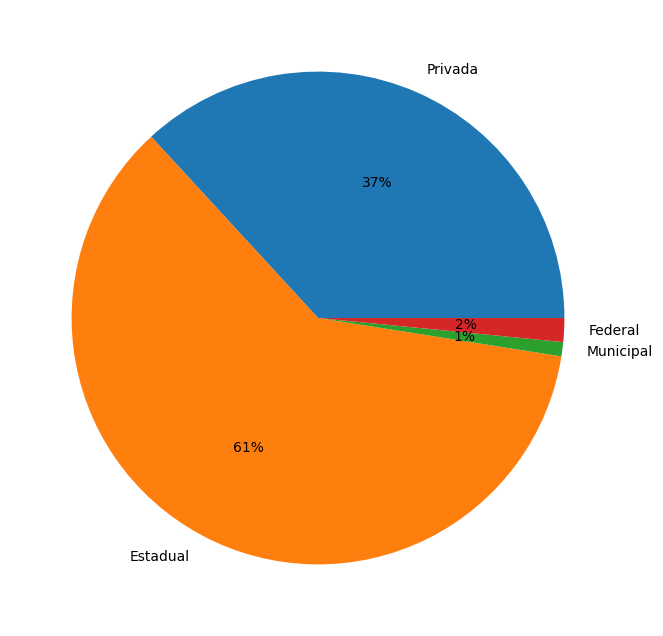

In [177]:
plt.figure(figsize=(16, 8))
data = [df.groupby(by=["TP_DEPENDENCIA_ADM_ESCOLA"]).count().NU_ANO[3], df.groupby(by=["TP_DEPENDENCIA_ADM_ESCOLA"]).count().NU_ANO[1],
        df.groupby(by=["TP_DEPENDENCIA_ADM_ESCOLA"]).count().NU_ANO[2],
        df.groupby(by=["TP_DEPENDENCIA_ADM_ESCOLA"]).count().NU_ANO[0]]
labels = ['Privada', 'Estadual', 'Municipal', 'Federal']
plt.pie(data, labels = labels, autopct='%.0f%%')
plt.show()


Gráfico 01: para a relação entre as variáveis de números inteiros com a target

<Figure size 1600x800 with 0 Axes>

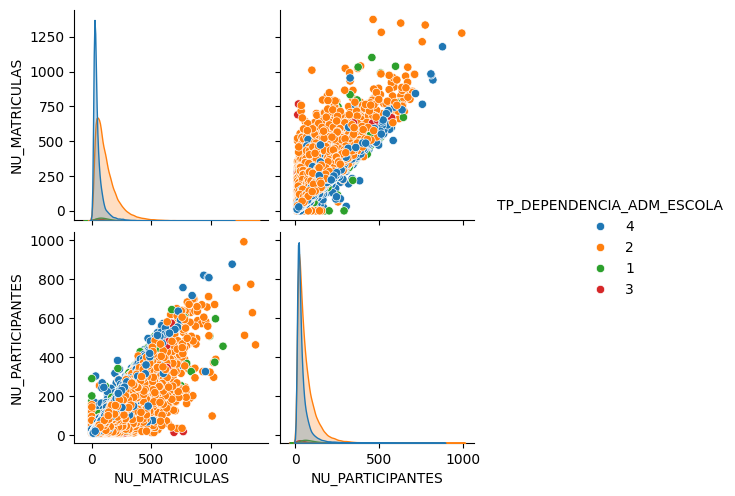

In [178]:
plt.figure(figsize=(16, 8))
sns.pairplot( data=df, vars=(
 'NU_MATRICULAS',
 'NU_PARTICIPANTES'), hue='TP_DEPENDENCIA_ADM_ESCOLA')

Gráfico 02: para a relação entre as variáveis de taxas com a target

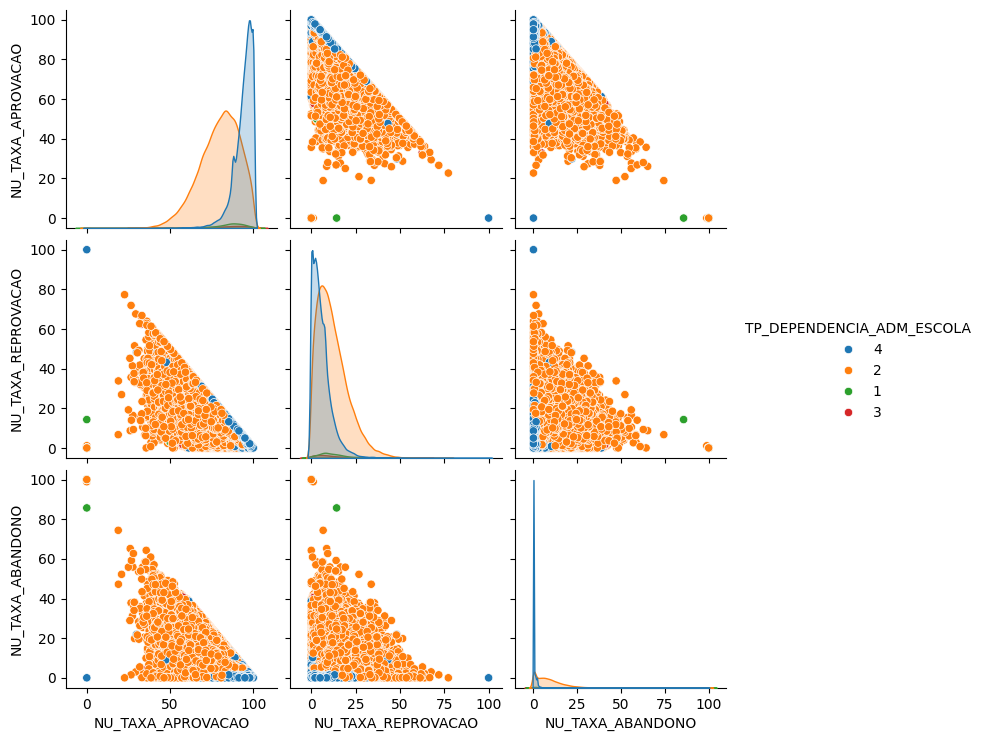

In [179]:
sns.pairplot( data=df, vars=(
 'NU_TAXA_APROVACAO',
 'NU_TAXA_REPROVACAO','NU_TAXA_ABANDONO'), hue='TP_DEPENDENCIA_ADM_ESCOLA' )

Gráfico 03: para a relação entre as variáveis de médias com a target

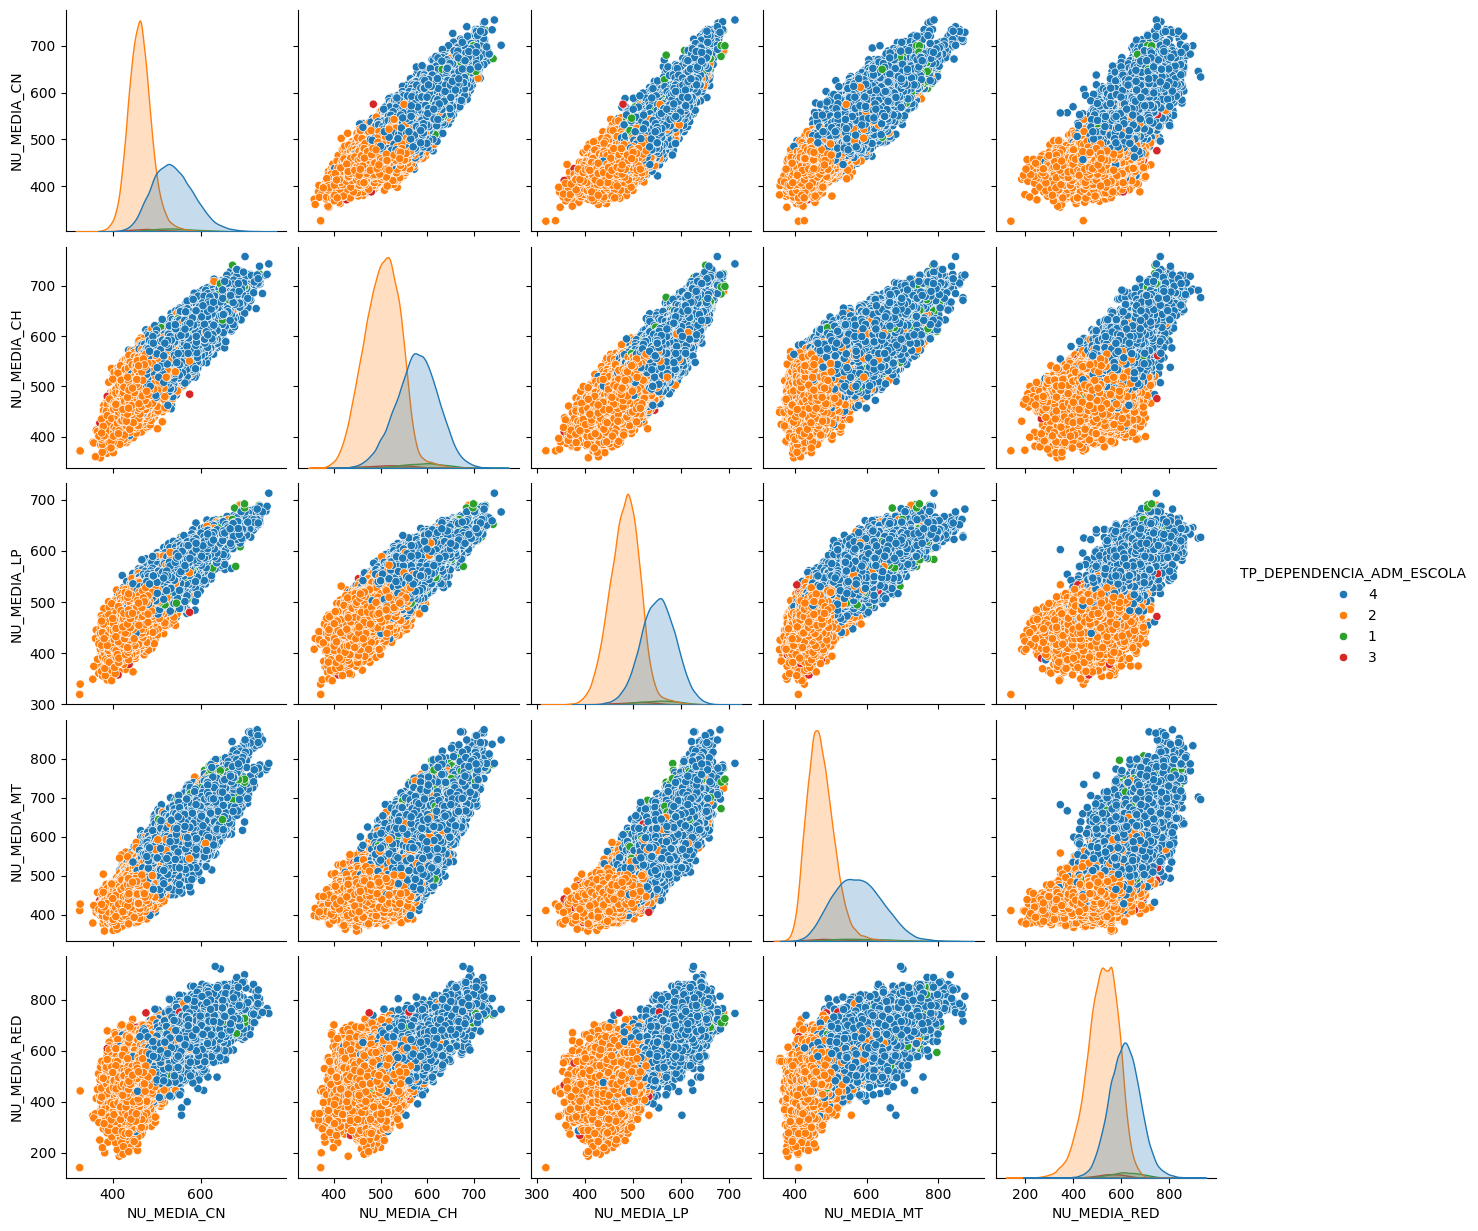

In [180]:
sns.pairplot( data=df, vars=('NU_MEDIA_CN',
 'NU_MEDIA_CH',
 'NU_MEDIA_LP',
 'NU_MEDIA_MT',
 'NU_MEDIA_RED'), hue='TP_DEPENDENCIA_ADM_ESCOLA')

* Observações de Todas as Medias das Notas de Redação, Ciências da Natureza, Ciências Humanas, Linguagens e Códigos, Matemátematica e Redação
 - Escolas Federais tem a maior valor máximo normal entre os demais, na sequência decrecente temos as Escolas Privadas, Escolas Municipais e por último as Estaduais
 - Analisando os valores "Out Liners" vemos que há mais equilíbrio entre as Escolas Federais e Escolas Municipais do que as Escolas Estaduais em relação as Privada

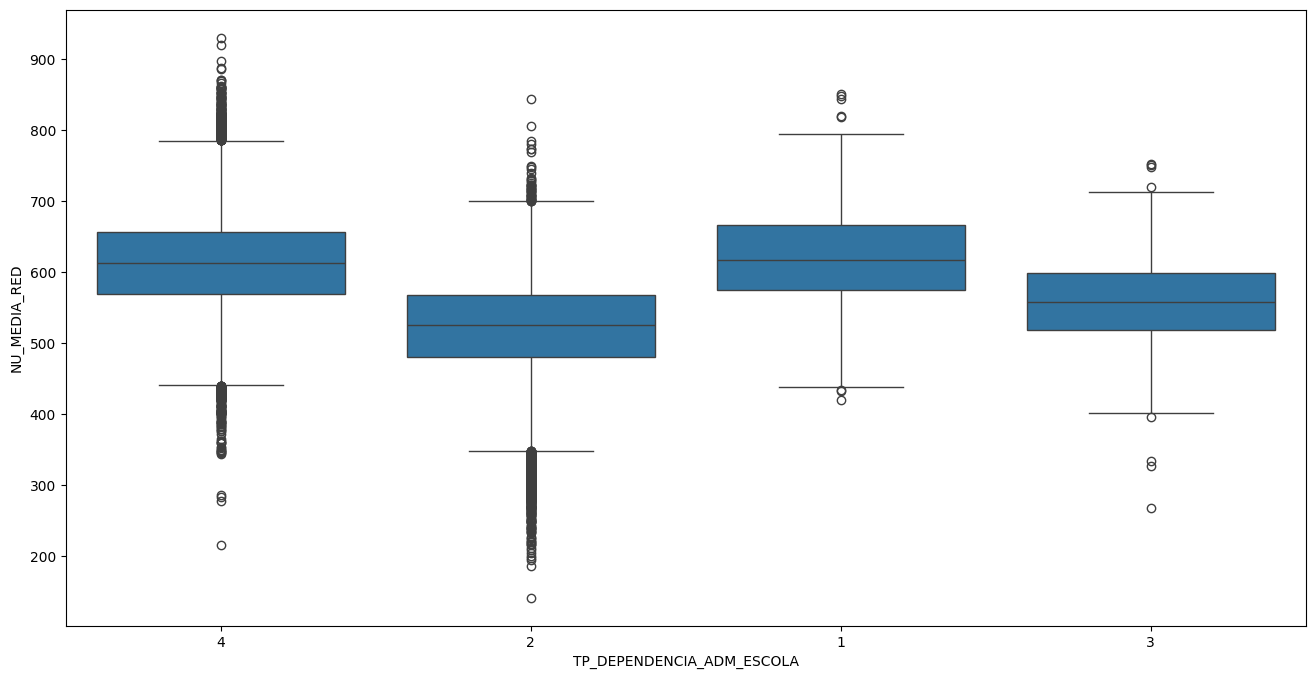

In [181]:
plt.figure(figsize=(16, 8))
ax = sns.boxplot(x="TP_DEPENDENCIA_ADM_ESCOLA", y="NU_MEDIA_RED", data=df)

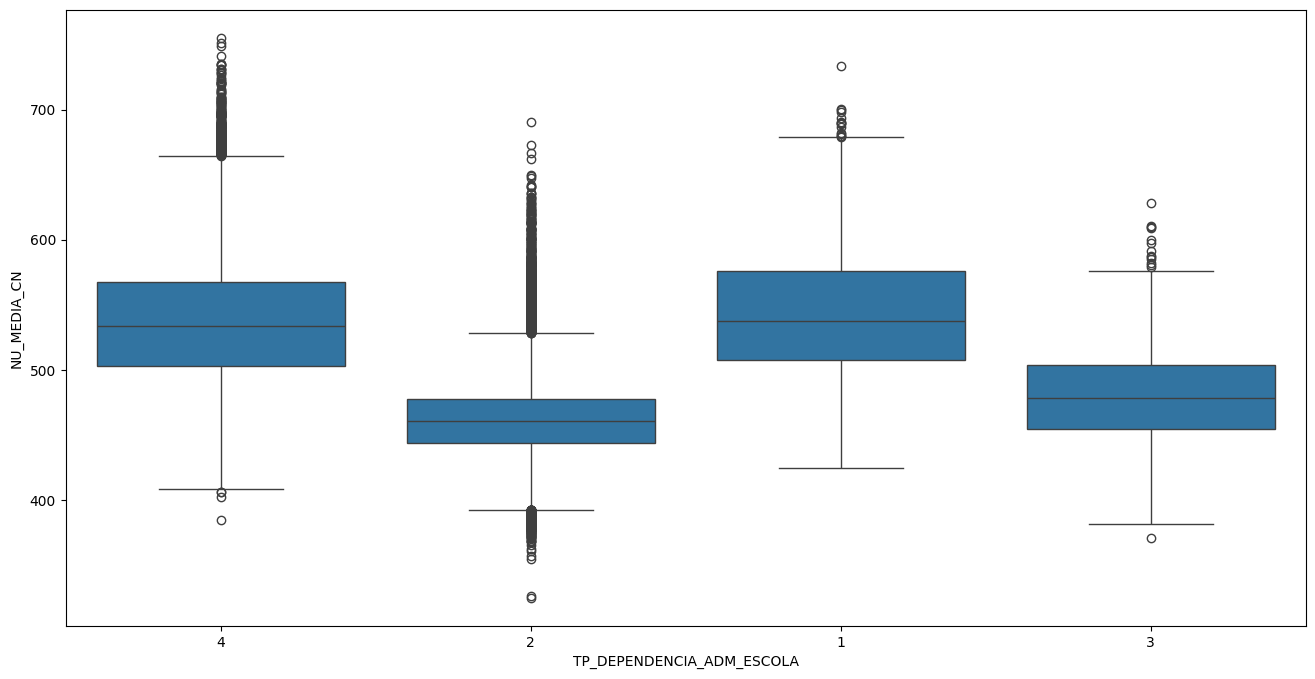

In [182]:
plt.figure(figsize=(16, 8))
ax = sns.boxplot(x="TP_DEPENDENCIA_ADM_ESCOLA", y="NU_MEDIA_CN", data=df)

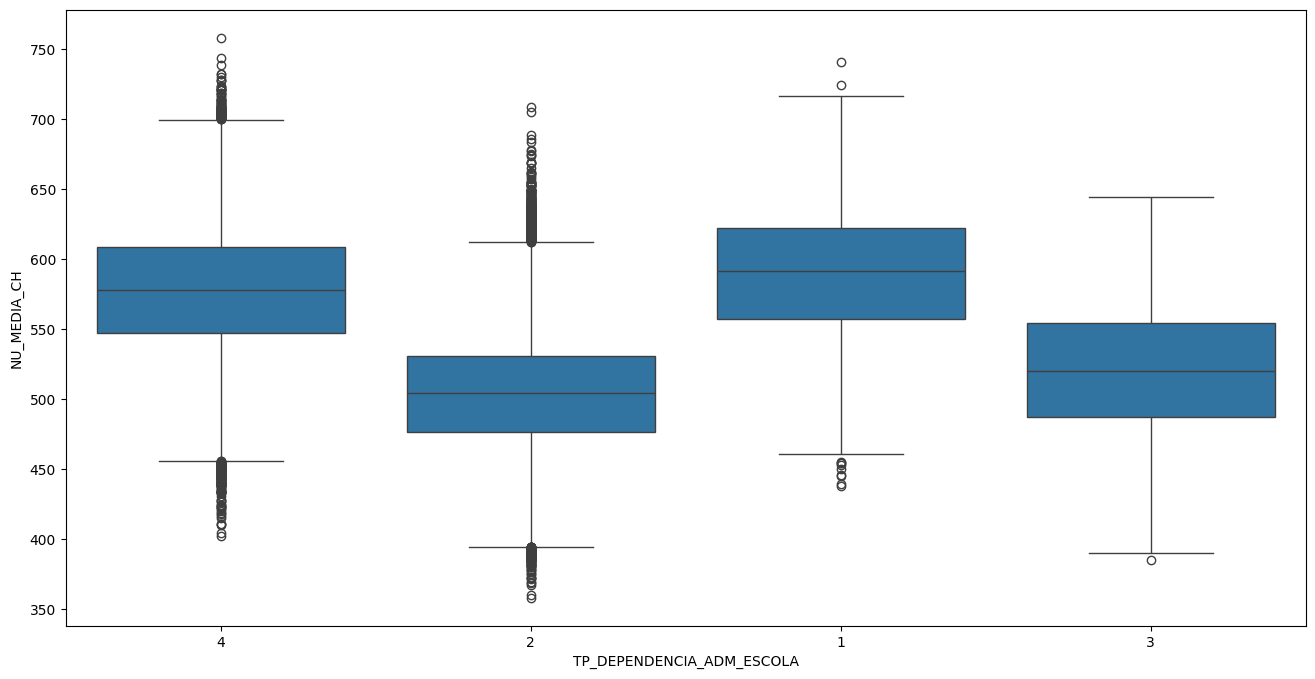

In [183]:
plt.figure(figsize=(16, 8))
ax = sns.boxplot(x="TP_DEPENDENCIA_ADM_ESCOLA", y="NU_MEDIA_CH", data=df)

Gráfico da média da nota de matemática no ENEM de cada tipo de administração escolar

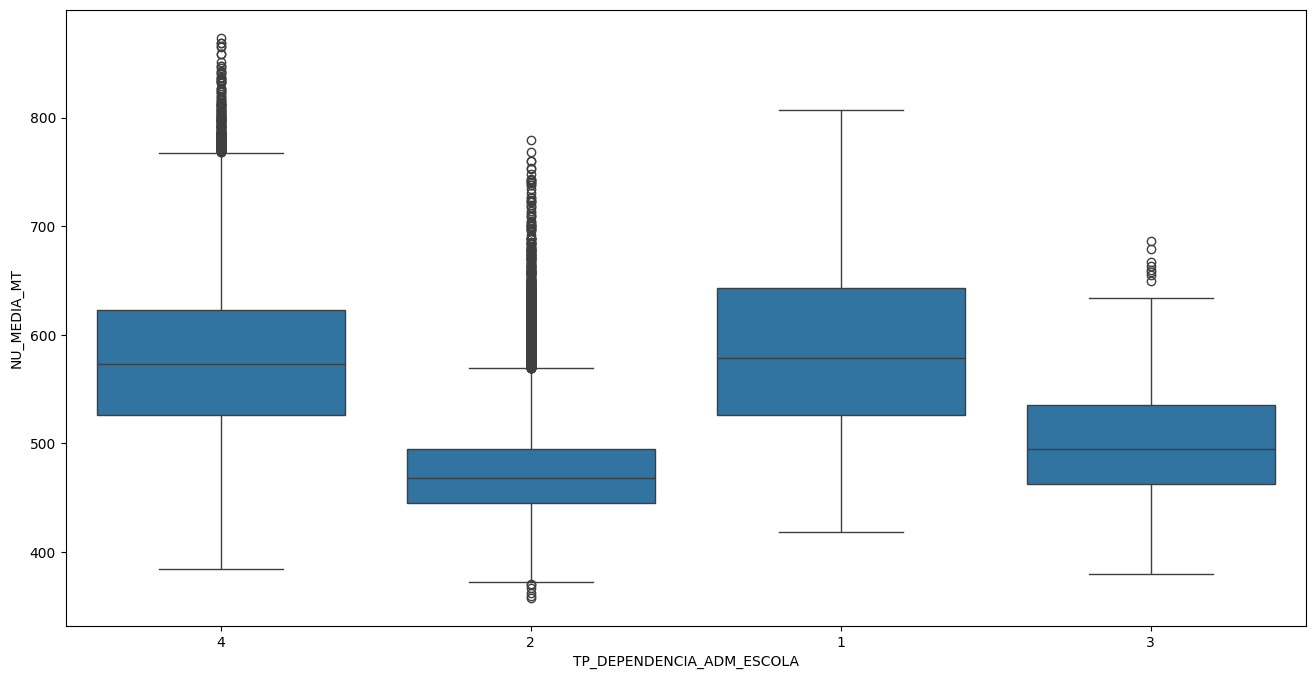

In [184]:
plt.figure(figsize=(16, 8))
ax = sns.boxplot(x="TP_DEPENDENCIA_ADM_ESCOLA", y="NU_MEDIA_MT", data=df)

Gráfico da média da nota de língua portuguesa no ENEM de cada tipo de administração escolar

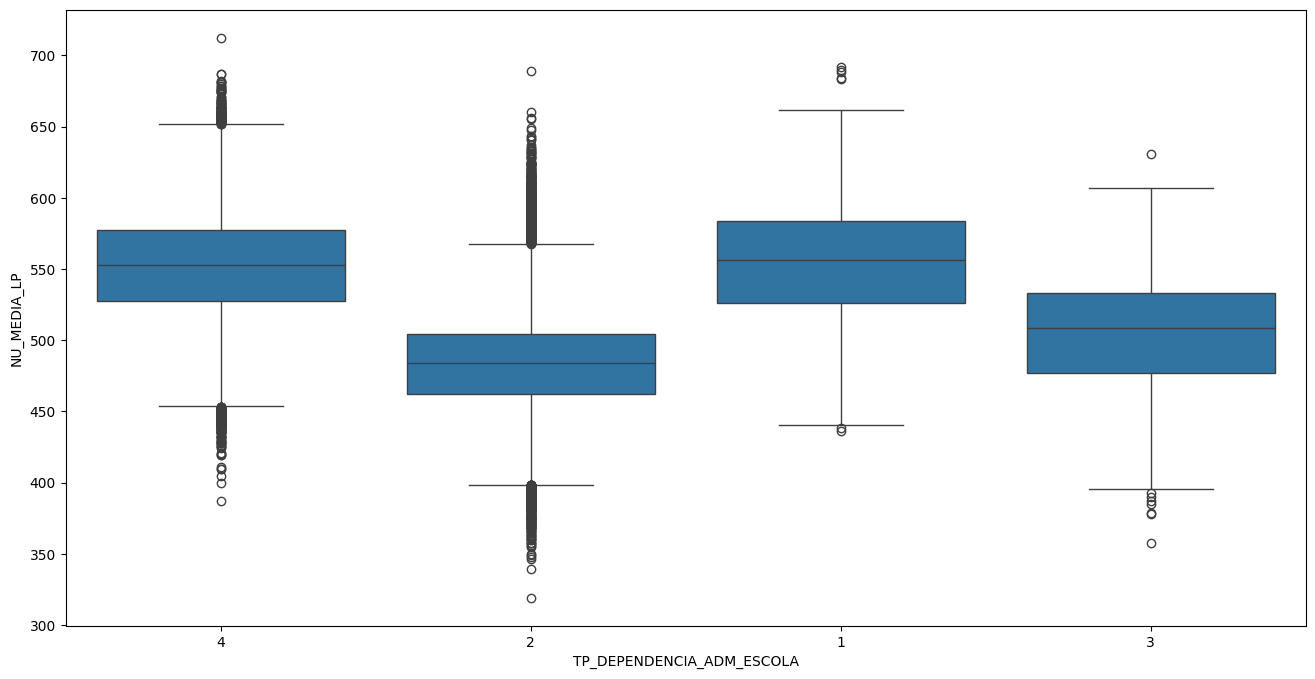

In [185]:
plt.figure(figsize=(16, 8))
ax = sns.boxplot(x="TP_DEPENDENCIA_ADM_ESCOLA", y="NU_MEDIA_LP", data=df)

Observações Do Gráfico da porcentagem de Escolas Localizadas em Região Urbana e Rural:
* 96% das escolas participantes do ENEM são de localidade Urbana e apenas 4% Rural

/tmp/ipykernel_1210/1581931269.py:2: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  data = [df.groupby(by=["TP_LOCALIZACAO_ESCOLA"]).count().NU_ANO[0], df.groupby(by=["TP_LOCALIZACAO_ESCOLA"]).count().NU_ANO[1]]
/tmp/ipykernel_1210/1581931269.py:2: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  data = [df.groupby(by=["TP_LOCALIZACAO_ESCOLA"]).count().NU_ANO[0], df.groupby(by=["TP_LOCALIZACAO_ESCOLA"]).count().NU_ANO[1]]


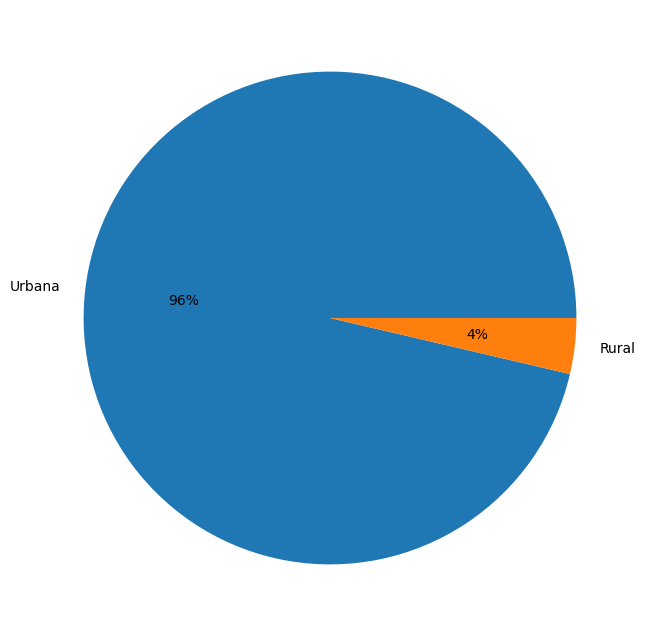

In [186]:
plt.figure(figsize=(16, 8))
data = [df.groupby(by=["TP_LOCALIZACAO_ESCOLA"]).count().NU_ANO[0], df.groupby(by=["TP_LOCALIZACAO_ESCOLA"]).count().NU_ANO[1]]
labels = ['Urbana', 'Rural']
plt.pie(data, labels = labels, autopct='%.0f%%')
plt.show()


#Separação dos dados em treino e teste e OneHotEncoder

In [187]:
df_cat = df[['CO_ESCOLA_EDUCACENSO', 'PORTE_ESCOLA', 'TP_LOCALIZACAO_ESCOLA']]

In [188]:
df[df_cat.columns].agg(['unique'])

,CO_ESCOLA_EDUCACENSO,PORTE_ESCOLA,TP_LOCALIZACAO_ESCOLA
unique,"[11000058, 11000171, 11000180, 11000198, 11000...","[Maior que 90 alunos, De 1 a 30 alunos, De 61 ...","[1, 2]"


In [189]:
X = df.drop(['TP_DEPENDENCIA_ADM_ESCOLA'], axis = "columns")
y = df.TP_DEPENDENCIA_ADM_ESCOLA

column_names_train = df.drop(['TP_DEPENDENCIA_ADM_ESCOLA'], axis = "columns").columns
column_name_target = df[['TP_DEPENDENCIA_ADM_ESCOLA']].columns

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.3, random_state = 13)

In [190]:
encoder_transformer = make_column_transformer(
    (OneHotEncoder(), ['TP_LOCALIZACAO_ESCOLA','PORTE_ESCOLA']),
    remainder = 'passthrough'
)
encoder_transformer.fit(X_train)
encoder_transformer.fit(X_test)

X_train_encoded = encoder_transformer.transform(X_train)
X_test_encoded = encoder_transformer.transform(X_test)

#Modelos de Previsão

Modelo Linear Logístico

In [191]:
from sklearn.linear_model import LogisticRegression
clf = LogisticRegression(random_state=0).fit(X_train_encoded, y_train)
y_pred = clf.predict(X_test_encoded)
y_prob = clf.predict_proba(X_test_encoded)
print(accuracy_score(y_test, y_pred))
confusion_matrix(y_test, y_pred)

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


0.8863310726908015


array([[    0,   110,     0,   377],
       [    0, 18026,     0,   923],
       [    0,   207,     0,    77],
       [    0,  1876,     0,  9811]])

In [192]:
Linear_acc = accuracy_score(y_test, y_pred)

Árvore de Decisão

In [193]:
clf = DecisionTreeClassifier()
clf = clf.fit(X_train_encoded, y_train) # o método fit "treina o modelo"
y_pred = clf.predict(X_test_encoded)
y_prob = clf.predict_proba(X_test_encoded)
print(accuracy_score(y_test, y_pred))
confusion_matrix(y_test, y_pred)

0.9113573407202216


array([[  181,    82,     6,   218],
       [   91, 17811,   255,   792],
       [    5,   169,    45,    65],
       [  237,   792,    72, 10586]])

In [194]:
DecisionTree_acc = accuracy_score(y_test, y_pred)

KNN

In [195]:
knn = KNeighborsClassifier()
knn.fit(X_train_encoded, y_train)
knnpreds = knn.predict(X_test_encoded)
print(accuracy_score(y_test, knnpreds))
confusion_matrix(y_test, knnpreds)

0.9489922628713344


array([[  378,    39,     0,    70],
       [   42, 18273,    30,   604],
       [    0,    71,   175,    38],
       [   78,   618,    12, 10979]])

In [196]:
KNN_acc = (accuracy_score(y_test, knnpreds))

Rede Neural

In [197]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
scaler.fit(X_train_encoded)
X_train_scaled = scaler.transform(X_train_encoded)
X_test_scaled = scaler.transform(X_test_encoded)

In [198]:
from sklearn.neural_network import MLPClassifier
clf = MLPClassifier(solver='lbfgs', alpha=1e-5,
                      random_state=11,hidden_layer_sizes=(10, 10))
clf.fit(X_train_scaled, y_train)
y_pred = clf.predict(X_test_scaled)
print(accuracy_score(y_test, y_pred))
confusion_matrix(y_test, y_pred)

0.9360652083930334


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:546: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  self.n_iter_ = _check_optimize_result("lbfgs", opt_res, self.max_iter)


array([[  148,    78,     0,   261],
       [   37, 18233,     0,   679],
       [    0,   220,     0,    64],
       [   52,   617,     0, 11018]])

In [199]:
Neural_acc = (accuracy_score(y_test, y_pred))

Random Florest

In [200]:
from sklearn.ensemble import RandomForestClassifier
rf = RandomForestClassifier()
rf.fit(X_train_scaled, y_train)

RandomForestClassifier()

In [201]:
rfpreds = rf.predict(X_test_scaled)

In [202]:
print(accuracy_score(y_test, rfpreds))

0.9420192950616104


In [203]:
RandomForest_acc = accuracy_score(y_test, rfpreds)

In [204]:
confusion_matrix(y_test, rfpreds)

array([[  153,    87,     0,   247],
       [   14, 18356,     0,   579],
       [    1,   217,     0,    66],
       [   21,   589,     0, 11077]])

#Tabela Comparativa dos Modelos de Previsão e Conclusão

In [205]:
model = ['Linear', 'Árvore de Decisão', 'KNN', 'Rede Neural', 'Random Florest']
acc = [Linear_acc,DecisionTree_acc,KNN_acc,Neural_acc,RandomForest_acc]
compare = pd.DataFrame(list(zip(model, acc)),
               columns =['model', 'accuracy'])
compare.sort_values(by=['accuracy'], ascending=False)

,model,accuracy
2,KNN,0.948992
4,Random Florest,0.942019
3,Rede Neural,0.936065
1,Árvore de Decisão,0.911357
0,Linear,0.886331


<h1>Resultado Final: O Melhor modelo para previsão do tipo administrativo da escola participante do enem foi o Random Florest<h1/>